In [10]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

who = [
    "BXII_S1", #: "BXII_S1_15mM_LV4_30nm",
    "BXII_S3", #: "BXII_S3_15mM_LV4_100nm",
    "BXII_S4", #: "BXII_S4_15mM_LV4_200nm",
    "BXII_S6", #: "BXII_S6_15mM_DOPC",
]
sample = "BXII_S6" 

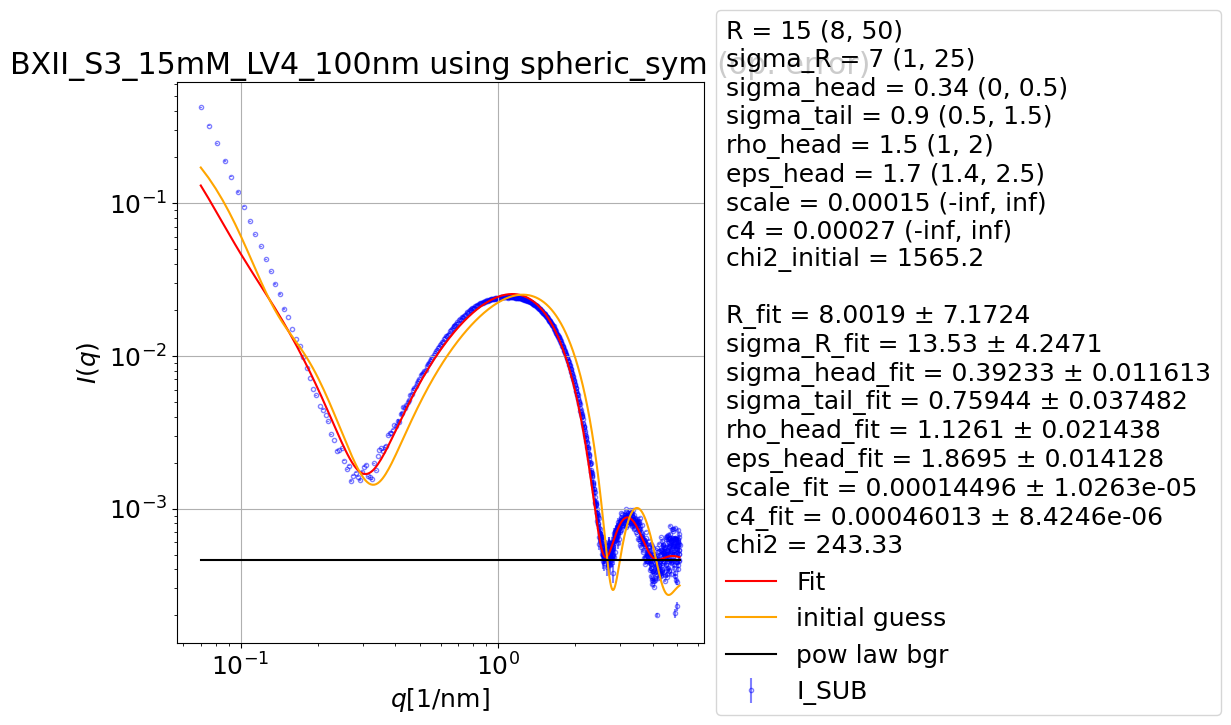

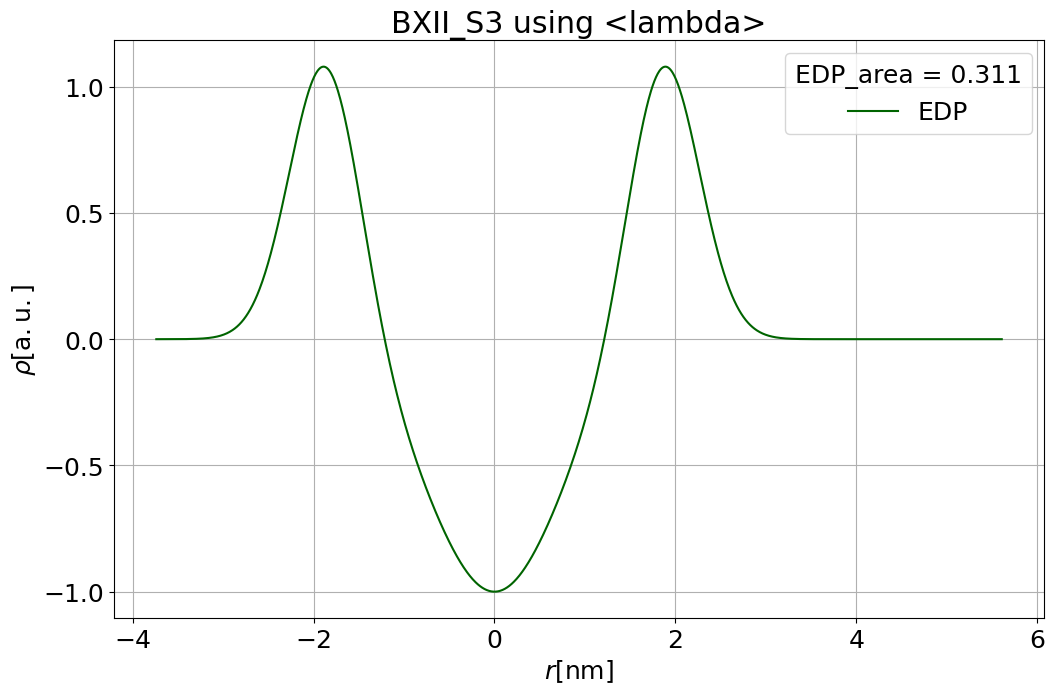

In [10]:
# SPHERIC SYM + c4
# sample = "BXII_S1" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
Ierr_Poisson = Ierr[mask]
I_err_op = BM29.Poisson_error_focus_minimum_highq(q, Ierr_Poisson)

fit_function = lambda q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale, c4: fit.ULV_spheric_sym(q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      0, 0, c4)
fit_function_name = "ULV_spheric_sym"
plt.close("all")

# ========================== Parameters ==========================
R       = 15
sigma_R = 7

sigma_head =0.34# 0.3929 
sigma_tail = 0.9
rho_head = 1.5 #1.2256 
eps_head = 1.7
scale = 0.00015
c2 = 0 
c3 = 0
c4 = 0.00027

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      c4] #,      c2,      c3,      c4]
lower_bounds = [   8,          1,        0.0,        0.5,        1,       1.4,  -np.inf, -np.inf] #,       0,       0,       0]
upper_bounds = [  50,         25,        0.5,        1.5,        2,       2.5,  +np.inf, +np.inf] #,   1e-10,   1e-10,   1e-10]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_op, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "sigma_head_fit", "sigma_tail_fit", 
               "rho_head_fit", "eps_head_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err_op, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)

#=========================== Plot ===========================================
q_fit = np.linspace(min(q), max(q), 1000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err_op, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, R, sigma_R, sigma_head, sigma_tail, rho_head,   eps_head,   scale, c4), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using spheric_sym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()
fig = fit.EDP_plot(R_fit, sigma_head_fit, sigma_head_fit, sigma_tail_fit, rho_head_fit, rho_head_fit, eps_head_fit, eps_head_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


[16.13, 7.523, 1.899, 0.7751, 0.3343, 0.429, 0.858, 1.755, 0.0001192, 0.000463]
R = 12 (10, 110)
sigma_R = 7 (2, 60)
rho_h1 = 1.3 (0, 4)
rho_h2 = 1.8 (0, 4)
sigma_h1 = 0.6 (0.13, 1)
sigma_h2 = 0.2 (0.13, 1)
sigma_c = 1.047 (0.5, 1.2)
z_h = 1.717 (1.5, 2)
scale = 0.000138 (0, 1)
c4 = 0.00062 (0, 1)
chi2_initial = 3267.1
 
R_fit = 16.134 ± 6.8656
sigma_R_fit = 7.5226 ± 2.0081
rho_h1_fit = 1.8993 ± 0.14883
rho_h2_fit = 0.77508 ± 0.11829
sigma_h1_fit = 0.3343 ± 0.041916
sigma_h2_fit = 0.42905 ± 0.045013
sigma_c_fit = 0.85799 ± 0.16194
z_h_fit = 1.7555 ± 0.036673
scale_fit = 0.00011925 ± 7.4031e-05
c4_fit = 0.00046297 ± 2.7521e-05
chi2 = 544.14


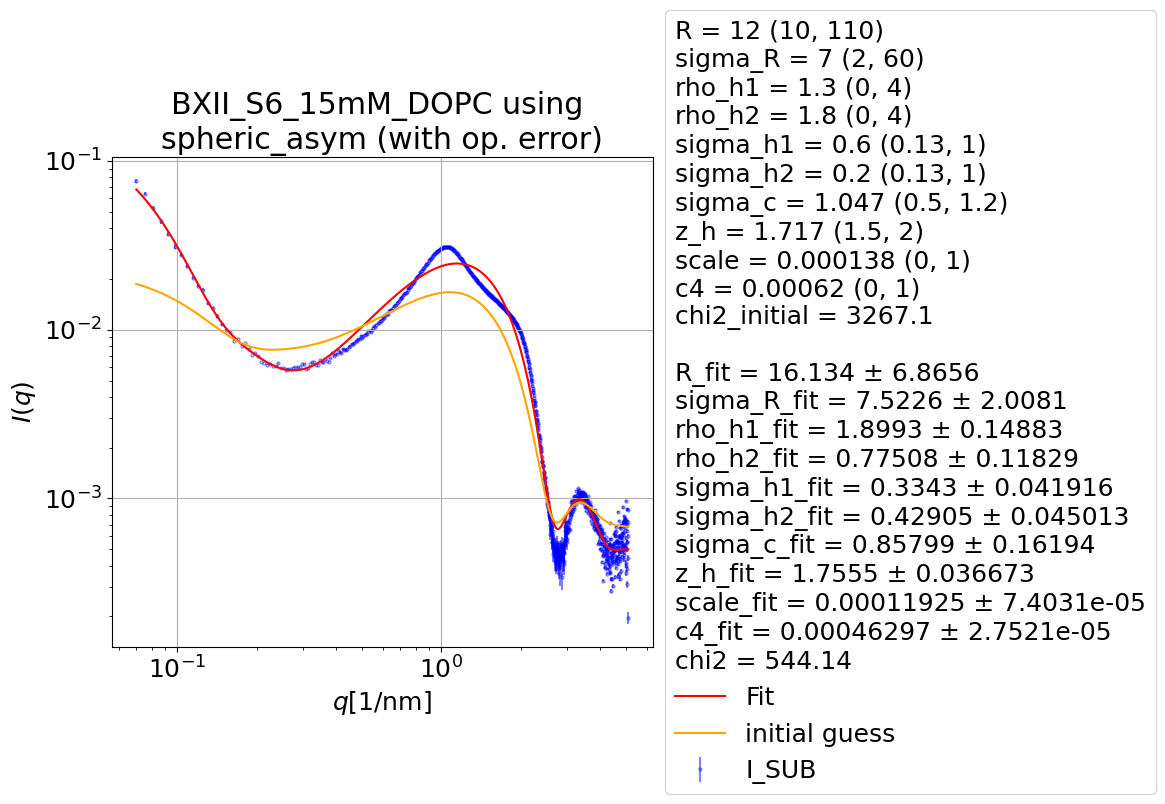

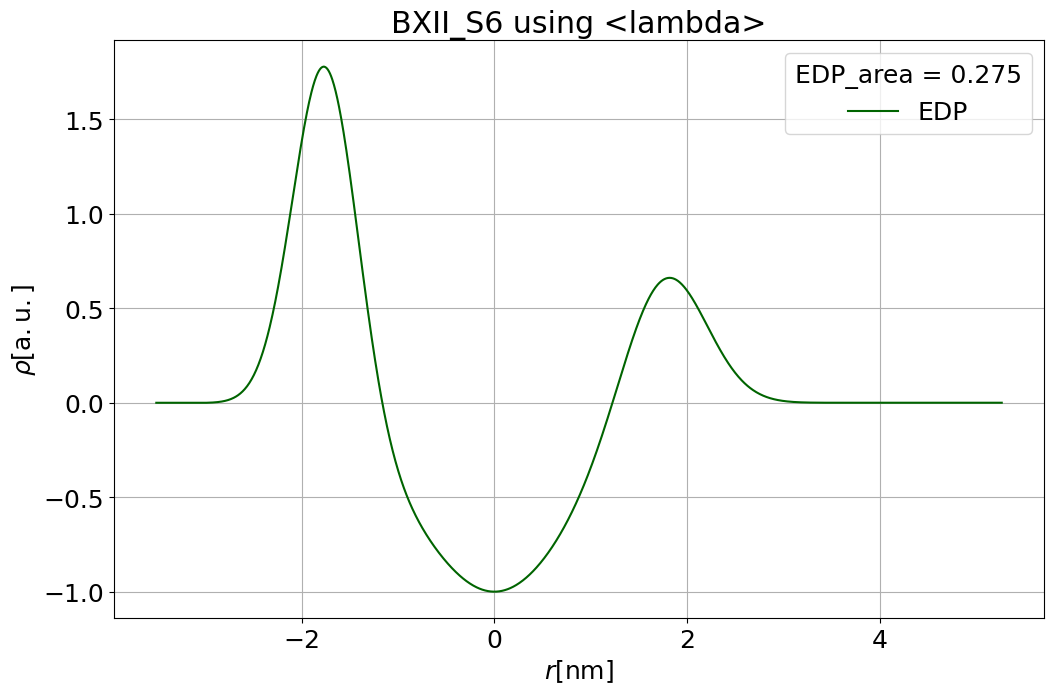

In [11]:
# SPHERIC ASYM + C4
# sample = "BXII_S1" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function_name = "ULV_spheric_asym_C4"
mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
Ierr_Poisson = Ierr[mask]
I_err_op = BM29.Poisson_error_focus_minimum_highq(q, Ierr_Poisson)

# ========================== Parameters ==========================
R = 18
sigma_R = 7
rho_h1 = 1.8
rho_h2 = 1.4
sigma_h1 = 0.2
sigma_h2 = 0.3
sigma_c = 0.75
z_h = 1.75
scale = 0.00013965
c4 = 0

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,   c4] #,      c2,      c3,      c4]
lower_bounds = [  10,          2,      0.0,      0.0,        0.13,      0.13,      0.5,    1.5,      0,   0] #,       0,       0, -np.inf]
upper_bounds = [ 110,         60,      4.0,      4.0,         1.0,       1.0,      1.2,      2,      1,   1] #,       4,     0.5, +np.inf]
p0 =   [12, 7, 1.3, 1.8, 0.6, 0.2, 1.047, 1.717, 0.000138, 0.00062]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err_op, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)

chi2, info_text_print = fit.all_info(q, I, I_err_op, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err_op, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using \nspheric_asym (with op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
